### SOLUTION ANALYTIQUE DE L'ÉQUATION DE HELMHOLTZ 2D

## 1) Solution analytique et troncature de la série.


In [1]:
import numpy as np
import matplotlib.pyplot as plt
import scipy.special as sp

## parametre du problème 

a = 5.0 # rayon du cercke
k = 1.0 # nombre d'onde
theta = np.arange(0,2*np.pi,np.pi/500) # valeurs de theta
#N = [1,5,10,15,20,25,30,35,40,45,49,50,55] # nombre de mode anguaire
N= 50

## on IMPLEMENTE LA SOLUTION ANALYTIQUE TRONQUÉ

def U_plus(r,theta,N,k,a):

    u_plus = 0 + 0j

    for n in range (-N,N+1):

        An = - (-1j)**n * sp.jv(n,k*a) / sp.hankel1(n,k*a) 
        u_plus += An * sp.hankel1(n,k*r) * np.exp(1j*n*theta)
    return u_plus



U_inc = lambda r,theta,k:np.exp(-1j*k*r*np.cos(theta))

Error =[]
for n in N:
    ErrorN = float(np.max(np.abs(U_plus(a,theta,n,k,a) + U_inc(a,theta,k))))
    Error.append(ErrorN )
    print([n,ErrorN])
plt.semilogy(N,Error,'r',label ='Courbe de erreur en fonction de N')
plt.xlabel('N')
plt.ylabel('ErrorN')
plt.xlim(0, 55)
plt.xticks(np.arange(0, 55, 5))

plt.ylim(1e-17, 1)
plt.yticks(10.0 ** np.arange(-16, 1, 2))
plt.legend()
#plt.savefig("convergence.png", dpi=300, bbox_inches="tight")
plt.show()     

TypeError: 'int' object is not iterable

## 2) Maillage de la fronctière 

In [2]:

def Geometrie_disque(R,N):

    angles = np.linspace(0,2*np.pi,N,endpoint = False)

    X = R*np.cos(angles) 
    Y = R*np.sin(angles) 
    Num_noeud = np.arange(N)
    
    # Noeuds = [ num_noeuds, xi,yi]
    Noeuds = np.transpose(np.vstack((Num_noeud,X,Y)))

    return Noeuds 

def Geometrie_polygone():

    X = np.array([1.0, 0.3, -0.8, -0.8, 0.3])
    Y = np.array([0.0, 0.95, 0.6, -0.6, -0.95])

    N = len(X)

    Num_noeud = np.arange(N)

    Noeuds = np.transpose(
        np.vstack((Num_noeud, X, Y))
    )

    return Noeuds









def Maillage(Noeuds):

    N = len(Noeuds)

    #Elements =[ [ num_elem, noeud_debut, noeud_fin] ]

    Elements = np.array( [ [ i, i , (i+1)%N  ] for i in range(N)] )
    
    np.set_printoptions(suppress=True)
    
    
    
    Milieux = []
    Longueurs = []
    Normales = []

    for k in range(N):   # pour chaque élement 

        # On recupere les numeros des noeuds qui le constituent

        i_k = Elements[k,1]
        j_k = Elements[k,2] 

        # Noeuds de l'éléments 

        ni = Noeuds[i_k]
        
        nj = Noeuds[j_k]
 
        # coordonnées de chaque noeuds 
        
        xi = ni[1]
        yi = ni[2]

        xj = nj[1]
        yj = nj[2]

        # On calcule lepoint milieu  M_k

        x_M = (xi + xj)/2
        y_M = (yi + yj)/2

        M_k = [ float(x_M),float( y_M) ]
        Milieux.append(M_k)


        # Longueur de l'élément 

        dx = xj - xi
        dy = yj - yi

        lk = float(np.sqrt((dx)**2 + (dy)**2))
        Longueurs.append(lk)

        # Normale exterieure

        n_k = [float(dy/lk),
            float(-dx/lk)]

        Normales.append(n_k)

    Milieux = np.array(Milieux)
    Longueurs = np.array(Longueurs)
    Normales = np.array(Normales)

    # Info_element[ point milieu, longueur, normale exterieur]
    
    for k in range(N):

        print(f"Élément {k} : ")
        print(f"Milieu = ({Milieux[k,0]:.6f},{Milieux[k,1]:.6f})")
        print(f"Longueur = {Longueurs[k]:.6f}")
        print(f"Normale = ({Normales[k,0]:.6f},{Normales[k,1]:.6f})")
        print(" ")
    



     ## On represente le maillage et quelques normale pour vérifier visuelement la construction   

    XX = Noeuds[:,1] 
    XX = np.append(XX,XX[0])
    YY = Noeuds[:,2] 
    YY = np.append(YY,YY[0])

    XM = Milieux[:,0] 
    YM = Milieux[:,1] 

    XN = Normales[:,0]
    YN = Normales[:,1]

    plt.plot(XX,YY,"b")
    plt.scatter(XM,YM,color = 'red')
    plt.quiver(XM,YM,XN,YN)
    plt.axis("equal")
    plt.savefig("maillage.png", dpi=300, bbox_inches="tight")
    
    plt.show()


        

    



    

Élément 0 : 
Milieu = (0.650000,0.475000)
Longueur = 1.180042
Normale = (0.805056,0.593199)
 
Élément 1 : 
Milieu = (-0.250000,0.775000)
Longueur = 1.154340
Normale = (-0.303204,0.952926)
 
Élément 2 : 
Milieu = (-0.800000,0.000000)
Longueur = 1.200000
Normale = (-1.000000,-0.000000)
 
Élément 3 : 
Milieu = (-0.250000,-0.775000)
Longueur = 1.154340
Normale = (-0.303204,-0.952926)
 
Élément 4 : 
Milieu = (0.650000,-0.475000)
Longueur = 1.180042
Normale = (0.805056,-0.593199)
 


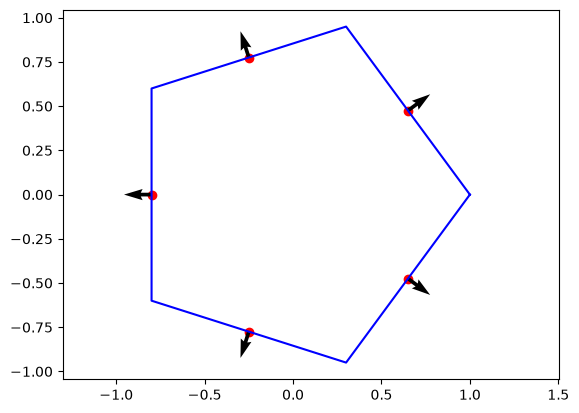

In [3]:
Maillage(Geometrie_polygone()) 

##  CALCUL DE LA TRACE NORMALE 

In [4]:
def q(r,theta,k,a,N):

    q = 0 + 0j

    for n in range(-N, N+1):

        q += (-k/2 * (-1j)**n * sp.jv(n,k*a) / sp.hankel1(n,k*a)* (sp.hankel1(n-1,k*r)- sp.hankel1(n+1,k*r)) * np.exp(1j*n*theta))

    return q 
        
## on verifie l'implementation 
#N =10
theta = np.linspace(0, 2*np.pi, 100, endpoint=False)

q_analytique = q(a, theta, k, a, N)

for h in [1e-2, 1e-3, 1e-4, 1e-5, 1e-6]:
    
    q_num = (
        U_plus(a+h, theta, N, k, a)
        - U_plus(a-h, theta, N, k, a)
    ) / (2*h)

    erreur = np.max(np.abs(q_analytique - q_num))

    print(f" ({h:.6f},{erreur:.6f})")

    

 (0.010000,0.000016)
 (0.001000,0.000000)
 (0.000100,0.000000)
 (0.000010,0.000000)
 (0.000001,0.000000)


## Construction de la donnée qui sera utilisée dans le TP1.

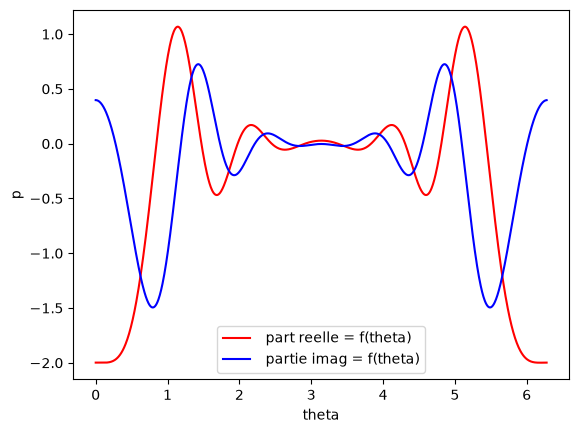

In [5]:
N = 25
a = 5.0
k = 1.0
Theta = np.linspace(0, 2*np.pi, 1000, endpoint=False)

def dU_inc(r,theta,k):
    
    return -1j*k*np.cos(theta)*np.exp(-1j*k*r*np.cos(theta))

def P(r,theta,k,a,N):

    return -q(a,theta,k,a,N) - dU_inc(a,theta,k)

## On represente ses parties relles et parties immaginaires lelong de la fronctière 
theta = np.linspace(0,2*np.pi,30,endpoint = False)
plt.plot(Theta,P(a,Theta,k,a,N).real,'r', label = " part reelle = f(theta)")
plt.plot(Theta,P(a,Theta,k,a,N).imag,'b',label = " partie imag = f(theta)")
plt.xlabel('theta')
plt.ylabel ('p')
plt.legend()
plt.savefig("parties relle et imaginaire de P",  dpi=300, bbox_inches="tight")
plt.show() 